# Lab 2 — Backpropagation in Multilayer Neural Networks (Completed)

> **Environment:** Python 3.11, TensorFlow 2.16.2 (Intel Mac), NumPy, scikit-learn, pandas, matplotlib. Select your `.venv311` kernel in VS Code and run cells from the top. These are **completed adapted versions** of the UofT-DSI Lab 1–3 materials, not byte-for-byte edits of the university's original notebooks.

## 1. Dataset and train/test split

train: (1437, 64) test: (360, 64)


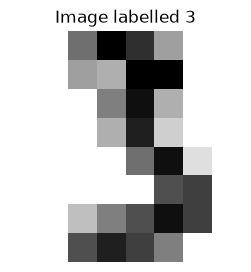

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
np.random.seed(42)
digits = load_digits()
X = digits.data.astype('float32')
y = digits.target.astype('int32')
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                     random_state=42, stratify=y)
print('train:', X_train.shape, 'test:', X_test.shape)
plt.figure(figsize=(3, 3))
plt.imshow(digits.images[45], cmap='gray_r', interpolation='nearest')
plt.title(f'Image labelled {digits.target[45]}')
plt.axis('off')
plt.show()

## 2. One-hot encoding, stable softmax and negative log likelihood

In [2]:
def one_hot(n_classes, y):
    return np.eye(n_classes)[np.asarray(y, dtype=int)]

def softmax(X):
    values = np.asarray(X, dtype=float)
    shifted = values - np.max(values, axis=-1, keepdims=True)
    exps = np.exp(shifted)
    return exps / np.sum(exps, axis=-1, keepdims=True)

def nll(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.clip(np.asarray(y_pred), 1e-15, 1.0)
    per_sample_loss = -np.sum(y_true * np.log(y_pred), axis=-1)
    return float(np.mean(per_sample_loss))

print('One-hot:', one_hot(10, [0, 4, 9, 1]))
print('Softmax:', softmax([10, 2, -3]))
print('Sums to one:', np.sum(softmax([10, 2, -3])))
print('Batch probabilities:', softmax(np.array([[10, 2, -3], [-1, 5, -20]])))
print('NLL correct high-confidence prediction:', nll([1, 0, 0], [.99, .01, 0]))
print('NLL incorrect high-confidence prediction:', nll([1, 0, 0], [.01, .01, .98]))
assert np.isclose(np.sum(softmax([10, 2, -3])), 1.0)

One-hot: [[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]]
Softmax: [9.99662391e-01 3.35349373e-04 2.25956630e-06]
Sums to one: 1.0
Batch probabilities: [[9.99662391e-01 3.35349373e-04 2.25956630e-06]
 [2.47262316e-03 9.97527377e-01 1.38536042e-11]]
NLL correct high-confidence prediction: 0.01005033585350145
NLL incorrect high-confidence prediction: 4.605170185988091


## 3. Completed Logistic Regression implementation

The missing `forward()` and `loss()` methods are implemented. A batch of samples is multiplied by a 64-by-10 matrix; `softmax` converts logits to class probabilities.

In [3]:
class LogisticRegression:
    def __init__(self, input_size, output_size):
        self.W = np.random.uniform(low=-0.1, high=0.1,
                                   size=(input_size, output_size))
        self.b = np.random.uniform(low=-0.1, high=0.1, size=output_size)
        self.input_size = input_size
        self.output_size = output_size

    def forward(self, X):
        X = np.asarray(X)
        logits = X @ self.W + self.b
        return softmax(logits)

    def predict(self, X):
        return np.argmax(self.forward(X), axis=-1)

    def loss(self, X, y):
        targets = one_hot(self.output_size, np.asarray(y, dtype=int))
        return nll(targets, self.forward(X))

    def grad_loss(self, X, y_true, y_pred):
        X, y_true = np.atleast_2d(X), np.atleast_2d(y_true)
        batch_size = X.shape[0]
        error = y_pred - y_true
        return (X.T @ error / batch_size, np.sum(error, axis=0) / batch_size)

lr = LogisticRegression(64, 10)
assert lr.forward(np.zeros((1, 64))).shape == (1, 10)
assert lr.loss(np.zeros((1, 64)), np.zeros(1)) > 0
print('Initial loss:', lr.loss(X_train, y_train))

Initial loss: 5.099469031988214


In [4]:
# Stochastic gradient descent: one sample per update.
logistic_history = []
for epoch in range(5):
    for i in np.random.permutation(len(X_train)):
        x, y_sample = X_train[i:i+1], y_train[i:i+1]
        probabilities = lr.forward(x)
        grad_W, grad_b = lr.grad_loss(x, one_hot(10, y_sample), probabilities)
        lr.W -= 0.01 * grad_W
        lr.b -= 0.01 * grad_b
    loss_value = lr.loss(X_train, y_train)
    accuracy_value = np.mean(lr.predict(X_test) == y_test)
    logistic_history.append((loss_value, accuracy_value))
    print(f'Epoch {epoch+1}: training NLL={loss_value:.3f}, test acc={accuracy_value:.3f}')

Epoch 1: training NLL=0.954, test acc=0.897
Epoch 2: training NLL=1.134, test acc=0.881
Epoch 3: training NLL=0.937, test acc=0.942
Epoch 4: training NLL=0.491, test acc=0.939
Epoch 5: training NLL=0.686, test acc=0.928


## 4. Sigmoid and its derivative

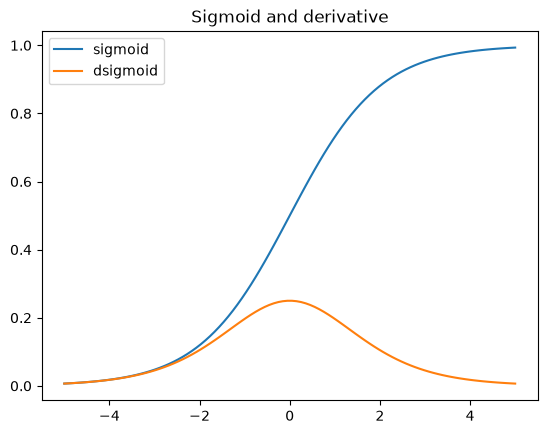

In [5]:
def sigmoid(X):
    X = np.clip(np.asarray(X, dtype=float), -500, 500)
    return 1 / (1 + np.exp(-X))

def dsigmoid(X):
    p = sigmoid(X)
    return p * (1 - p)

x_curve = np.linspace(-5, 5, 100)
plt.plot(x_curve, sigmoid(x_curve), label='sigmoid')
plt.plot(x_curve, dsigmoid(x_curve), label='dsigmoid')
plt.legend()
plt.title('Sigmoid and derivative')
plt.show()

## 5. Completed neural-network backpropagation

We use a **sigmoid hidden layer** and a **softmax output layer**. The output-layer gradient of cross-entropy with softmax is `y_pred - y_true`; it is propagated backwards through the sigmoid derivative.

In [6]:
class NeuralNet:
    def __init__(self, input_size, hidden_size, output_size):
        self.W_h = np.random.uniform(-0.1, 0.1, (input_size, hidden_size))
        self.b_h = np.random.uniform(-0.1, 0.1, hidden_size)
        self.W_o = np.random.uniform(-0.1, 0.1, (hidden_size, output_size))
        self.b_o = np.random.uniform(-0.1, 0.1, output_size)
        self.input_size, self.hidden_size, self.output_size = input_size, hidden_size, output_size

    def forward_hidden(self, X):
        self.Z_h = np.atleast_2d(X) @ self.W_h + self.b_h
        return sigmoid(self.Z_h)

    def forward_output(self, H):
        self.Z_o = H @ self.W_o + self.b_o
        return softmax(self.Z_o)

    def forward(self, X):
        hidden = self.forward_hidden(X)
        return self.forward_output(hidden)

    def loss(self, X, y):
        return nll(one_hot(self.output_size, np.asarray(y, dtype=int)), self.forward(X))

    def grad_loss(self, X, y_true):
        X = np.atleast_2d(X)
        targets = one_hot(self.output_size, np.asarray(y_true, dtype=int))
        probabilities = self.forward(X)
        batch_size = X.shape[0]
        error_o = (probabilities - targets) / batch_size
        hidden = sigmoid(self.Z_h)
        grad_W_o = hidden.T @ error_o
        grad_b_o = np.sum(error_o, axis=0)
        error_h = (error_o @ self.W_o.T) * dsigmoid(self.Z_h)
        grad_W_h = X.T @ error_h
        grad_b_h = np.sum(error_h, axis=0)
        return {'W_h': grad_W_h, 'b_h': grad_b_h, 'W_o': grad_W_o, 'b_o': grad_b_o}

    def train(self, x, y, learning_rate):
        x = np.atleast_2d(x)
        y = np.atleast_1d(y)
        grads = self.grad_loss(x, y)
        for name, gradient in grads.items():
            setattr(self, name, getattr(self, name) - learning_rate * gradient)

    def predict(self, X):
        return np.argmax(self.forward(X), axis=-1)

    def accuracy(self, X, y):
        return np.mean(self.predict(X) == y)

nn = NeuralNet(64, 32, 10)
assert nn.forward(np.zeros((1, 64))).shape == (1, 10)
assert nn.loss(np.zeros((1, 64)), np.zeros(1)) > 0
print('Backprop test passed')

Backprop test passed


Epoch  1: loss=2.1290, train=0.654, test=0.661
Epoch  2: loss=1.8921, train=0.737, test=0.717
Epoch  3: loss=1.6449, train=0.824, test=0.814
Epoch  4: loss=1.4108, train=0.878, test=0.853
Epoch  5: loss=1.2035, train=0.888, test=0.867
Epoch  6: loss=1.0359, train=0.906, test=0.883
Epoch  7: loss=0.8885, train=0.933, test=0.903
Epoch  8: loss=0.7719, train=0.935, test=0.928
Epoch  9: loss=0.6802, train=0.944, test=0.931
Epoch 10: loss=0.6038, train=0.953, test=0.939
Epoch 11: loss=0.5396, train=0.958, test=0.942
Epoch 12: loss=0.4855, train=0.960, test=0.942
Epoch 13: loss=0.4422, train=0.961, test=0.944
Epoch 14: loss=0.4039, train=0.967, test=0.953
Epoch 15: loss=0.3707, train=0.970, test=0.953


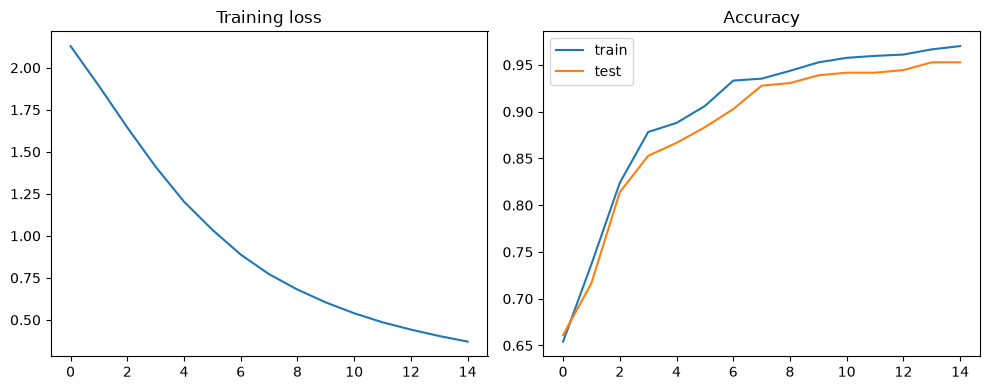

In [7]:
# Train the network with stochastic gradient descent.
model = NeuralNet(64, 32, 10)
losses, train_accuracies, test_accuracies = [], [], []
for epoch in range(15):
    for index in np.random.permutation(len(X_train)):
        model.train(X_train[index], y_train[index], learning_rate=0.001)
    losses.append(model.loss(X_train, y_train))
    train_accuracies.append(model.accuracy(X_train, y_train))
    test_accuracies.append(model.accuracy(X_test, y_test))
    print(f'Epoch {epoch+1:2d}: loss={losses[-1]:.4f}, '
          f'train={train_accuracies[-1]:.3f}, test={test_accuracies[-1]:.3f}')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(losses)
axes[0].set_title('Training loss')
axes[1].plot(train_accuracies, label='train')
axes[1].plot(test_accuracies, label='test')
axes[1].set_title('Accuracy')
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Completed exercise: Worst prediction errors

Worst five indices: [228  93  51   3  89]


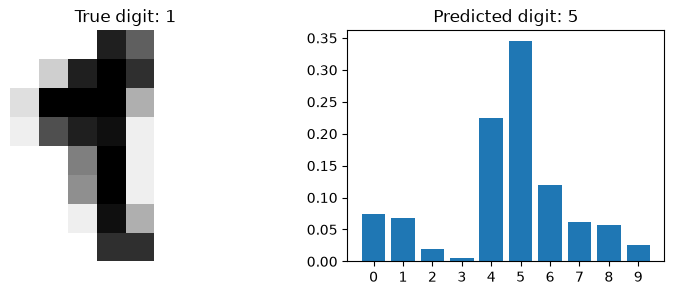

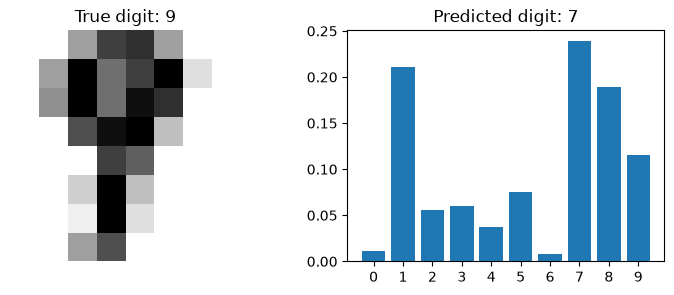

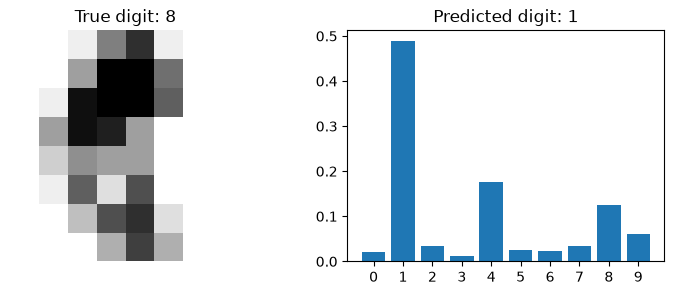

In [8]:
def plot_prediction(model, sample_idx=0):
    probabilities = model.forward(X_test[sample_idx:sample_idx+1])[0]
    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    axes[0].imshow(X_test[sample_idx].reshape(8, 8), cmap='gray_r')
    axes[0].set_title(f'True digit: {y_test[sample_idx]}')
    axes[0].axis('off')
    axes[1].bar(np.arange(10), probabilities)
    axes[1].set_title(f'Predicted digit: {np.argmax(probabilities)}')
    axes[1].set_xticks(np.arange(10))
    plt.show()

probabilities = model.forward(X_test)
true_class_probability = probabilities[np.arange(len(X_test)), y_test]
worst_indices = np.argsort(true_class_probability)[:5]
print('Worst five indices:', worst_indices)
for index in worst_indices[:3]:
    plot_prediction(model, int(index))

**Answer:** The least-confident correct-class predictions can be hard even for a person because 8×8 images lose detail. Whether a specific case is recognizable depends on the displayed output. Look at the plotted images rather than claiming an unverified result.

## 7. Completed exercise: Hyperparameter experiments

Vary **learning rate** and **hidden-layer width** using fresh models. A second hidden layer is tested using a Keras model to avoid assuming the hand-coded single-hidden-layer class already supports it.

In [9]:
import pandas as pd
settings = [(0.0003, 10), (0.001, 10), (0.003, 10),
            (0.001, 32), (0.003, 32)]
trials = []
for rate, width in settings:
    candidate = NeuralNet(64, width, 10)
    for epoch in range(5):
        for index in np.random.permutation(len(X_train)):
            candidate.train(X_train[index], y_train[index], learning_rate=rate)
    trial_accuracy = candidate.accuracy(X_test, y_test)
    trials.append({'Learning rate': rate, 'Hidden neurons': width,
                   'Test accuracy': trial_accuracy})
    print(f'lr={rate}, hidden={width}: accuracy={trial_accuracy:.3f}')
results = pd.DataFrame(trials)
display(results.sort_values('Test accuracy', ascending=False))

lr=0.0003, hidden=10: accuracy=0.239
lr=0.001, hidden=10: accuracy=0.700
lr=0.003, hidden=10: accuracy=0.883
lr=0.001, hidden=32: accuracy=0.872
lr=0.003, hidden=32: accuracy=0.947


,Learning rate,Hidden neurons,Test accuracy
4,0.0030,32,0.947222
2,0.0030,10,0.883333
3,0.0010,32,0.872222
1,0.0010,10,0.700000
0,0.0003,10,0.238889


In [10]:
# Additional second-hidden-layer experiment using TensorFlow/Keras.
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
import tensorflow as tf

keras_results = []
for hidden_layers in (1, 2):
    layers = [Input(shape=(64,))]
    layers.extend(Dense(32, activation='sigmoid') for _ in range(hidden_layers))
    layers.append(Dense(10, activation='softmax'))
    candidate = Sequential(layers)
    candidate.compile(optimizer=Adam(learning_rate=0.001),
                      loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    candidate.fit(X_train, y_train, epochs=5, batch_size=32, verbose=0)
    _, accuracy = candidate.evaluate(X_test, y_test, verbose=0)
    keras_results.append((hidden_layers, accuracy))
print('Number of hidden layers and test accuracies:', keras_results)

2026-11-11 02:03:24.067837: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Number of hidden layers and test accuracies: [(1, 0.8805555701255798), (2, 0.800000011920929)]


**Interpretation:** Test accuracy is used to compare settings, but selecting parameters based repeatedly on the test set can bias the final estimate. In a more rigorous project, tune on a validation set and evaluate once on a held-out test set. Results vary because training uses random initialization and sampling.